# Завдання №1 — Тест-план

## Мета та гіпотези

Оцінити, чи збільшує новий підхід до розміщення онлайн-реклами кількість покупок. Контрольна група отримує попередній рекламний підхід, тестова — новий. Конкретні зміни в рекламі в умові не описані; їх потрібно зафіксувати до старту експерименту.

**Прийняте рішення плану:** основна метрика — середня кількість покупок за день за полем `# of Purchase`. Це кількість покупок, а не унікальних покупців. Більше покупок означає кращий результат за цією метрикою.

Різниця $\Delta = \overline{Purchase}_{test} - \overline{Purchase}_{control}$. Нульова гіпотеза $H_0: \Delta = 0$; альтернативна $H_1: \Delta \ne 0$. Бізнес-очікування — додатна різниця. Метрика та гіпотези не задані умовою; тут вони є рішеннями тест-плану.


## Дизайн експерименту

- **Запропонована одиниця розподілу — користувач.** До показу експериментальної реклами випадково розподіляємо користувачів цільової аудиторії між групами у співвідношенні 1:1. Критерії включення фіксуємо до запуску.
- Зберігаємо призначення користувача протягом усього тесту та виключаємо одночасне потрапляння в обидві групи. Витрати й покупки відносимо до групи за однаковими, заздалегідь визначеними правилами атрибуції та вікном обліку покупок.
- Запускаємо групи одночасно. Залишаємо однаковими продукт, ціни, сайт і правила обліку. Умови аудиторії, бюджету та розміщення узгоджуємо так, щоб відмінності відповідали лише заздалегідь описаному рекламному підходу.
- До старту фіксуємо обидва рекламні підходи й налаштування; під час тесту не змінюємо їх та не переносимо користувачів між групами.

**Доступна одиниця спостереження в CSV — день для кожної групи**, а основна метрика — середнє за спільні дні. Це не користувацькі дані: статистичний аналіз має враховувати доступний рівень агрегації, спільні календарні умови та можливу залежність між днями.

## Розмір вибірки, тривалість і правило рішення

**Прийняті рішення плану:** fixed horizon, двостороння перевірка з рівнем значущості $\alpha=0.05$ та цільовою статистичною потужністю 80%.

До запуску визначаємо базову середню кількість покупок за день, мінливість парних денних різниць і мінімальне практично важливе збільшення кількості покупок за день (MDE). На основі порівнянних історичних даних оцінюємо потрібну тривалість. Умова не містить цих параметрів, тому числовий MDE та необхідну кількість днів не вигадуємо.

До старту фіксуємо дату завершення: тривалість має охоплювати цілі тижневі цикли, забезпечувати запланований обсяг даних і повне вікно обліку покупок. Не зупиняємо тест достроково через проміжний результат і не продовжуємо лише заради значущості.

Для порівняння використовуємо paired t-test: пара — результати двох груп за той самий календарний день. Метод припускає незалежність різниць між днями та приблизну нормальність їхнього розподілу; pairing сам по собі не усуває часову залежність. Якщо ці припущення не обґрунтовані, статистичний висновок залишається умовним.

**Критерій успіху:** середня кількість покупок за день у тестовій групі вища, двостороннє p-value менше 0.05 за допустимих припущень методу, а оцінене збільшення не менше за заздалегідь обраний MDE. Без виконання всіх умов успіх не підтверджено.


# Завдання №2 — Трекінг-план

## Спільні атрибути

План описує збір подій для майбутнього експерименту; поденні CSV не містять такого рівня деталізації.

| Атрибут | Призначення |
|---|---|
| `event_id` | Унікальний ідентифікатор події для усунення повторної доставки. |
| `event_name` | Назва події з таблиці нижче. |
| `occurred_at` | Час фактичної події у форматі ISO 8601 із timezone; зберігаємо в UTC, спільну reporting timezone для денних зрізів фіксуємо до старту. |
| `user_id` | Псевдонімний стабільний ідентифікатор користувача для зв'язування його подій і призначення групи; без прямих персональних даних. |
| `session_id` | Ідентифікатор сесії для подій сайту; для призначення та платформних рекламних подій — лише якщо застосовно. |
| `experiment_id`, `variant` | Ідентифікатор експерименту та `control` або `test`, отримані з початкового призначення користувача. |
| `campaign_id`, `ad_id` | Ідентифікатори кампанії та оголошення для рекламних подій; для подій сайту — за наявності встановленого зв'язку атрибуції. |

На стороні рекламної платформи стабільний `user_id` може бути недоступний. Для user-level порівняння потрібне підтримуване й узгоджене зв'язування призначення, показу або кліку та подій сайту. Невідомі значення не підміняємо вигаданими ідентифікаторами: події без такого зв'язку не підтверджують користувацький шлях або належність до групи.

## Події та умови фіксації

Спільні атрибути застосовуються до всіх подій з урахуванням зазначених обмежень. У таблиці наведено додаткові атрибути.

| `event_name` | Коли фіксуємо | Додаткові атрибути |
|---|---|---|
| `experiment_assigned` | Після першого збереженого призначення користувача, до експериментального рекламного впливу. | `assignment_id` — ідентифікатор призначення; `assignment_version` — версія правил розподілу. |
| `ad_impression` | Коли платформа зареєструвала показ за спільним для груп визначенням. | `impression_id` — ідентифікатор показу, якщо доступний; `assignment_id` — за можливості зв'язування. |
| `ad_click` | Коли зафіксовано клік на оголошення. | `click_id` — ідентифікатор кліку; `impression_id` — якщо платформа підтримує зв'язок із показом; `landing_url` — адреса переходу без персональних даних. |
| `search` | Після виконання пошуку на сайті. | `search_id` — ідентифікатор запиту; `results_count` — кількість результатів. |
| `view_content` | Після відображення сторінки товару або іншого вмісту. | `content_id`, `content_type` — об'єкт і тип перегляду; для товару — `product_id`. |
| `add_to_cart` | Після успішного додавання товару до кошика. | `cart_id`, `product_id`, `quantity` — кошик, товар і додана кількість. |
| `purchase` | Коли замовлення вперше набуло заздалегідь погодженого статусу підтвердження покупки. | `order_id` — унікальне замовлення; `order_status` — підтверджений статус. |

Для подій сайту зберігаємо `assignment_id` та, якщо доступно, атрибуційний `click_id` або `impression_id` через узгоджений зв'язок переходу й сесії. `variant` беремо з призначення, а не довільного UTM-параметра. Правила атрибуції, її вікно та облік переходів між сесіями визначаємо однаково для груп до запуску; конкретна тривалість і технічні можливості платформ умовою не задані.

## Правила обліку та витрати

- Повторну доставку подій усуваємо за `event_id`. `purchase` додатково дедуплікуємо за `order_id`: повторне відкриття сторінки підтвердження або повторне повідомлення про статус не є новою покупкою.
- Кількість подій, покупок і унікальних користувачів розрізняємо. Один користувач може виконати кілька пошуків, додавань до кошика або оформити кілька замовлень.
- Для послідовної воронки перевіряємо порядок `ad_impression → ad_click → search → view_content → add_to_cart → purchase` за `occurred_at` для пов'язаного користувача. Не всі користувачі проходять усі кроки; пропущені події не відновлюємо припущеннями. Єдине вікно проходження воронки та правила вибору повторних кроків фіксуємо до старту однаково для груп.

**Витрати для контролю бюджету — окремий поденний звіт рекламної платформи, а не користувацька подія.** Мінімальні поля: `date`, `campaign_id`, `experiment_id`, `variant`, `spend`, `currency`. На кожну комбінацію дати, кампанії та групи має припадати один підсумковий запис, без повторного додавання оновлених версій звіту. Зв'язок кампанії з групою фіксуємо в налаштуваннях експерименту; якщо кампанія містить обидві групи, потрібен фактичний платформний розподіл витрат за групою, а не довільне ділення.

Для основної метрики підраховуємо підтверджені покупки відповідної групи за день за узгодженими правилами атрибуції; витрати підсумовуємо окремо для контролю бюджету. Дата витрат і дата подій мають відповідати спільній reporting timezone; валюта має бути однакова (для наданих даних — USD). Користувацькі події самі по собі не відновлюють рекламні витрати.

# Завдання №3 — Результати тесту та статистична значущість

## Підготовка даних і середня кількість покупок

Читаємо CSV з роздільником `;` та зіставляємо групи за датою. В обох файлах є 30 унікальних дат від 01.08 до 30.08.2019 без повторних рядків. У control за 05.08 відсутні покупки: це пропуск, а не нуль. Виключаємо цей день з обох груп без заповнення; залишається 29 пар дат. Висновок стосується цих спільних спостережуваних днів; перенесення на повний період потребує припущення про допустимість пропуску.

Обчислюємо середню кількість покупок за день і різницю `test − control`. Сумарні витрати на тих самих днях наводимо для контексту: бюджети різні, тому кількість покупок не відокремлює ефект бюджету та не вимірює ефективність витрат.


In [1]:
import pandas as pd
from scipy.stats import ttest_rel

columns = ["# of Purchase", "Spend [USD]"]
groups = {}
for group in ["control", "test"]:
    frame = pd.read_csv(f"{group}_group.csv", sep=";")
    frame["Date"] = pd.to_datetime(frame["Date"], format="%d.%m.%Y")
    groups[group] = frame.set_index("Date")[columns]

paired = pd.concat(groups, axis=1).dropna().sort_index()
summary = pd.DataFrame({
    group: {
        "mean_daily_purchases": paired[group]["# of Purchase"].mean(),
        "total_spend_usd": paired[group]["Spend [USD]"].sum(),
    }
    for group in groups
}).T
delta = summary.loc["test", "mean_daily_purchases"] - summary.loc["control", "mean_daily_purchases"]
display(summary.round(4))
print(f"Різниця середніх (test − control): {delta:.4f} покупки/день")


,mean_daily_purchases,total_spend_usd
control,522.7931,66818.0
test,512.7241,74595.0


Різниця середніх (test − control): -10.0690 покупки/день


## Перевірка різниці середніх

Застосовуємо [`scipy.stats.ttest_rel`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html): кожна пара — кількість покупок у test і control за той самий календарний день. Перевіряємо $H_0:\Delta=0$ проти $H_1:\Delta\ne0$, двостороннє p-value, $\alpha=0.05$.

Paired t-test припускає незалежність денних різниць між собою та приблизно нормальний розподіл цих різниць. Pairing враховує спільну дату, але не виправляє часову залежність. Наявність 29 пар не гарантує виконання припущень; тому p-value і висновок трактуємо умовно, без причинного твердження про рекламний підхід.


In [2]:
result = ttest_rel(
    paired["test"]["# of Purchase"],
    paired["control"]["# of Purchase"],
    alternative="two-sided",
)
alpha = 0.05
print(f"t = {result.statistic:.4f}; двостороннє p-value = {result.pvalue:.4f}")
print(f"Відхиляємо H₀ за α = {alpha}: {result.pvalue < alpha}")


t = -0.2063; двостороннє p-value = 0.8380
Відхиляємо H₀ за α = 0.05: False


## Інтерпретація

На 29 спільних днях середня кількість покупок становить **522.7931 покупки/день** у control та **512.7241 покупки/день** у test. Різниця `test − control` — **−10.0690 покупки/день**: описово у тестовій групі покупок менше. Витрати за цей період: **66 818 USD** у control та **74 595 USD** у test.

Paired t-test дає **t = −0.2063**, двостороннє **p-value = 0.8380 > 0.05**. За припущеннями тесту **не відхиляємо H₀**: статистично значущої відмінності середньої кількості покупок не виявлено. Це не доводить рівність груп або відсутність ефекту; через можливу часову залежність висновок умовний.

**Успіх нового підходу не підтверджено:** спостережуване середнє не збільшилося, значущості немає; числовий MDE не заданий, тому практичну достатність ефекту повністю оцінити неможливо. Результат описує обсяг покупок за різних бюджетів, а не ефективність витрат. Рандомізація та відсутність перетину груп не підтверджені CSV, тому причинний вплив рекламного підходу не встановлено.


# Завдання №4 — Воронки обох груп

Порівнюємо суми показників за тими самими 29 спільними днями, що й у №3: 01–30.08.2019 без 05.08 в обох групах, без заповнення пропусків. Порядок кроків: `Impressions → Website Clicks → Searches → View Content → Add to Cart → Purchase`.

Показів набагато більше, тому їх винесено в окрему панель; обидві панелі мають лінійні осі зі своїм масштабом та підписи точних кількостей. Це поденні агрегати, а не підтверджені послідовні шляхи тих самих користувачів; різниця між сусідніми кроками не встановлює індивідуальний відтік.


Matplotlib is building the font cache; this may take a moment.


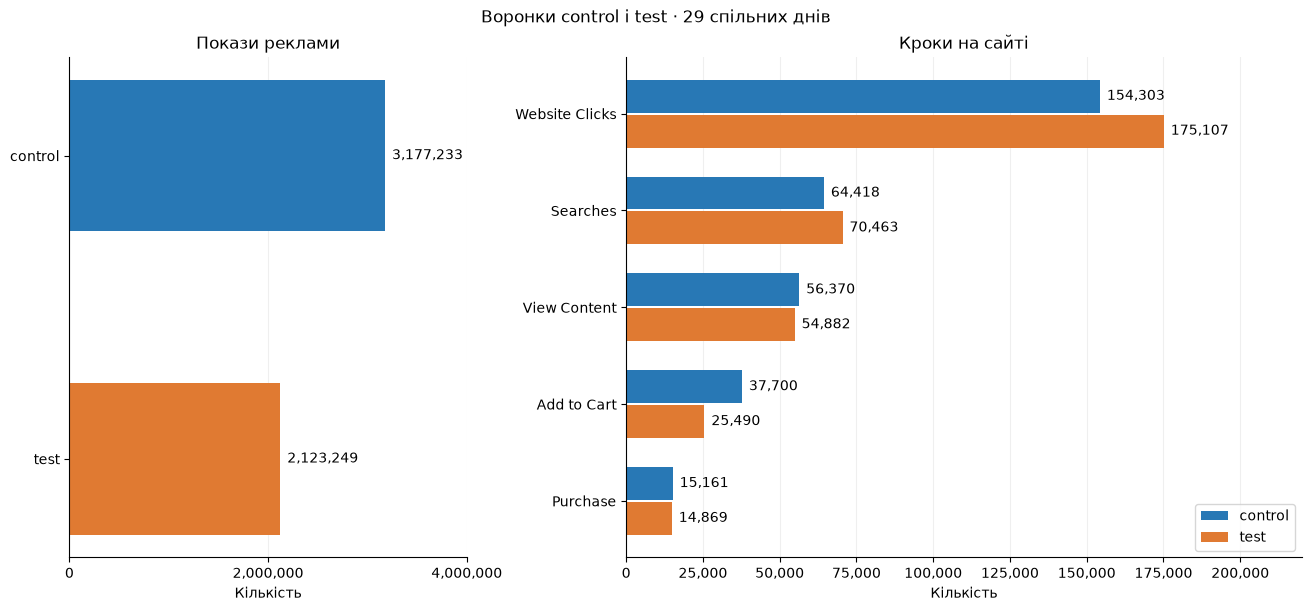

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

stages = ["Impressions", "Website Clicks", "Searches", "View Content", "Add to Cart", "Purchase"]
funnel_totals = {}
for group in ["control", "test"]:
    funnel_frame = pd.read_csv(f"{group}_group.csv", sep=";")
    funnel_frame["Date"] = pd.to_datetime(funnel_frame["Date"], format="%d.%m.%Y")
    funnel_totals[group] = funnel_frame.set_index("Date").loc[
        paired.index, [f"# of {stage}" for stage in stages]
    ].sum().to_numpy()

colors = {"control": "#2878B5", "test": "#E07A32"}
fig, axes = plt.subplots(1, 2, figsize=(13, 6), width_ratios=[1, 1.7], layout="constrained")
for index, group in enumerate(["control", "test"]):
    impression_bars = axes[0].barh(index, funnel_totals[group][0], color=colors[group], height=0.5)
    axes[0].bar_label(impression_bars, labels=[f"{funnel_totals[group][0]:,.0f}"], padding=5)
    positions = [step + (index - 0.5) * 0.36 for step in range(5)]
    stage_bars = axes[1].barh(positions, funnel_totals[group][1:], height=0.34, color=colors[group], label=group)
    axes[1].bar_label(stage_bars, labels=[f"{value:,.0f}" for value in funnel_totals[group][1:]], padding=5)

axes[0].set(yticks=[0, 1], yticklabels=["control", "test"], title="Покази реклами", xlim=(0, 4_000_000))
axes[1].set(yticks=range(5), yticklabels=stages[1:], title="Кроки на сайті", xlim=(0, 220_000))
for axis in axes:
    axis.invert_yaxis()
    axis.set_xlabel("Кількість")
    axis.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    axis.grid(axis="x", alpha=0.2)
    axis.set_axisbelow(True)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_xticks([0, 2_000_000, 4_000_000])
axes[1].legend(loc="lower right")
fig.suptitle("Воронки control і test · 29 спільних днів")
plt.show()


## Висновки з візуалізації

- У test менше показів: **2 123 249** проти **3 177 233** у control, але більше кліків: **175 107** проти **154 303**. В обох групах кількість кліків набагато менша за кількість показів.
- Пошуків у test більше: **70 463** проти **64 418**, а переглядів вмісту менше: **54 882** проти **56 370**.
- Додавань до кошика в test помітно менше: **25 490** проти **37 700**; кількість покупок ближча між групами: **14 869** проти **15 161**, також нижча в test. Більша кількість кліків і пошуків не супроводжується більшою кількістю покупок у цих агрегатах.

Це описові відмінності обсягів за різних бюджетів. Візуалізація не встановлює статистичної значущості, причин відмінностей або індивідуального проходження воронки.


# Завдання №5 — Довірчий інтервал різниці конверсій

Для переходу `Add to Cart → Purchase` використовуємо ті самі 29 спільних днів, що й у №4, без 05.08 в обох групах. Конверсія $p_g = Purchase_g / AddToCart_g$, різниця $\Delta = p_{test} - p_{control}$.

**Прийняте рішення:** двосторонній 95% довірчий інтервал за нормальним наближенням Wald з окремими оцінками дисперсії груп ([NIST](https://www.itl.nist.gov/div898/software/dataplot/refman1/auxillar/diffprop.htm)):

$$SE = \sqrt{\frac{p_{test}(1-p_{test})}{n_{test}} + \frac{p_{control}(1-p_{control})}{n_{control}}}, \qquad CI_{95\%} = \Delta \pm z_{0.975}SE,$$

де $n_g$ — кількість додавань до кошика. Різницю та межі інтервалу подаємо в процентних пунктах (п.п.).

Біноміальне наближення умовне на незалежних спробах, не більш як одній покупці в межах відповідної спроби з кошиком та відсутності перетину груп. Агреговані CSV не підтверджують зв'язок покупок із кошиками або незалежність повторних дій; це модельний інтервал для агрегованої конверсії, а не доведена user-level конверсія чи причинний ефект.


In [4]:
from math import sqrt
from scipy.stats import norm

cart_counts = {group: funnel_totals[group][-2] for group in ["control", "test"]}
purchase_counts = {group: funnel_totals[group][-1] for group in ["control", "test"]}
conversion = {group: purchase_counts[group] / cart_counts[group] for group in cart_counts}
conversion_difference = conversion["test"] - conversion["control"]
conversion_se = sqrt(sum(conversion[group] * (1 - conversion[group]) / cart_counts[group] for group in cart_counts))
margin = norm.ppf(0.975) * conversion_se
conversion_ci = (conversion_difference - margin, conversion_difference + margin)

for group in ["control", "test"]:
    print(f"{group}: {purchase_counts[group]:,.0f} покупок / {cart_counts[group]:,.0f} додавань до кошика = {conversion[group]:.2%}")
print(f"Різниця конверсій (test − control): {conversion_difference * 100:.2f} п.п.")
print(f"95% довірчий інтервал: [{conversion_ci[0] * 100:.2f}; {conversion_ci[1] * 100:.2f}] п.п.")


control: 15,161 покупок / 37,700 додавань до кошика = 40.21%
test: 14,869 покупок / 25,490 додавань до кошика = 58.33%
Різниця конверсій (test − control): 18.12 п.п.
95% довірчий інтервал: [17.34; 18.90] п.п.


## Інтерпретація

Агрегована конверсія `Add to Cart → Purchase` становить **40.21%** у control і **58.33%** у test. Різниця `test − control` — **+18.12 п.п.**, її 95% довірчий інтервал — **[17.34; 18.90] п.п.**

Інтервал повністю вище нуля: за припущеннями моделі перехід у test вищий. Це інша метрика, тому результат не доводить більшої кількості покупок за день чи виконання критерію успіху основної метрики.
